In [1]:
import json
import heapq
import random
from pathlib import Path

import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

device = "mps" if torch.backends.mps.is_available() else "cpu"
print(device)

# same data and split as every other notebook
images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())
image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)
print(len(test_ids))

# rebuild Faster R-CNN exactly like in training, then load the saved weights
model = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=256)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
model.load_state_dict(torch.load("src/faster-rcnn/01-baseline/model.pt", map_location=device))
model.to(device)
model.eval()

cutoff = 0.8   # best cutoff on validation

mps
5184


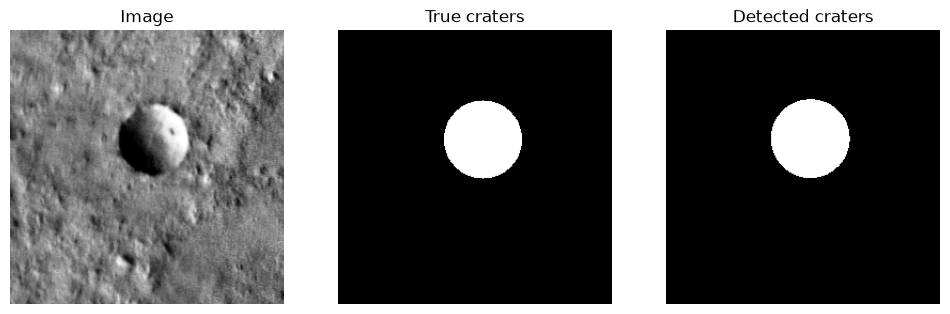

In [2]:
def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]
    for x, y, w, h in boxes:
        cx = x + w / 2
        cy = y + h / 2
        r = max(w, h) / 2
        inside = (xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2
        mask[inside] = 1
    return mask


def load_image(image_id):
    image = Image.open(images_path / f"{image_id}.png").convert("RGB")
    return torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255.0


def detect_boxes(image_id):
    # Faster R-CNN gives (x1, y1, x2, y2); convert to (x, y, w, h) like the labels
    with torch.no_grad():
        out = model([load_image(image_id).to(device)])[0]
    keep = out["scores"] > cutoff
    return [[x1, y1, x2 - x1, y2 - y1] for x1, y1, x2, y2 in out["boxes"][keep].cpu().tolist()]


# test on one image
image_id = test_ids[0]
true_map = make_mask(data[image_id])
detected_map = make_mask(detect_boxes(image_id))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
axes[0].set_title("Image")
axes[1].imshow(true_map, cmap="gray")
axes[1].set_title("True craters")
axes[2].imshow(detected_map, cmap="gray")
axes[2].set_title("Detected craters")
for ax in axes:
    ax.axis("off")
plt.show()

In [3]:
moves = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]

def heuristic(a, b):
    # shortest possible distance with 8 moves and no obstacles
    dy, dx = abs(a[0] - b[0]), abs(a[1] - b[1])
    return max(dy, dx) + (2 ** 0.5 - 1) * min(dy, dx)


def astar(blocked, start, goal):
    # blocked: 256x256 array, 1 = no-go; start, goal: (row, col)
    open_list = [(heuristic(start, goal), 0.0, start)]
    came_from = {start: None}
    cost_so_far = {start: 0.0}

    while open_list:
        _, cost, cell = heapq.heappop(open_list)
        if cell == goal:
            path = []
            while cell is not None:
                path.append(cell)
                cell = came_from[cell]
            return path[::-1]
        if cost > cost_so_far[cell]:
            continue   # an older, worse entry for this cell

        for dy, dx in moves:
            ny, nx = cell[0] + dy, cell[1] + dx
            if not (0 <= ny < 256 and 0 <= nx < 256) or blocked[ny, nx]:
                continue
            new_cost = cost + (2 ** 0.5 if dy and dx else 1.0)
            if new_cost < cost_so_far.get((ny, nx), float("inf")):
                cost_so_far[(ny, nx)] = new_cost
                came_from[(ny, nx)] = cell
                heapq.heappush(open_list, (new_cost + heuristic((ny, nx), goal), new_cost, (ny, nx)))

    return None   # no path exists

path length (cells): 256


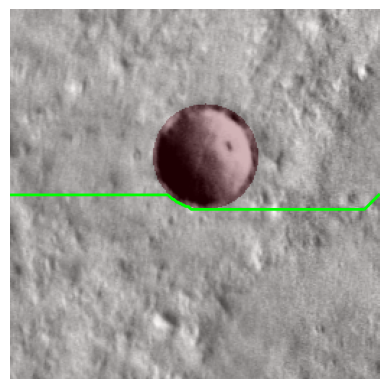

In [4]:
start, goal = (128, 0), (128, 255)
path = astar(detected_map, start, goal)

if path is None:
    print("no path")
else:
    print("path length (cells):", len(path))
    ys, xs = zip(*path)
    plt.imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
    plt.imshow(true_map, cmap="Reds", alpha=0.3)
    plt.plot(xs, ys, color="lime", linewidth=2)
    plt.axis("off")
    plt.show()

In [5]:
from torchvision.ops import box_iou

def path_length(path):
    return sum(2 ** 0.5 if (a[0] != b[0] and a[1] != b[1]) else 1.0 for a, b in zip(path, path[1:]))


def craters_entered(path, true_boxes):
    # indices of true craters whose circle contains at least one path cell
    ys = np.array([p[0] for p in path]) + 0.5
    xs = np.array([p[1] for p in path]) + 0.5
    entered = []
    for i, (x, y, w, h) in enumerate(true_boxes):
        cx, cy, r = x + w / 2, y + h / 2, max(w, h) / 2
        if np.any((xs - cx) ** 2 + (ys - cy) ** 2 <= r ** 2):
            entered.append(i)
    return entered


def was_detected(true_box, detected_boxes):
    # same rule as our scoring: a detected box with IoU >= 0.5
    if len(detected_boxes) == 0:
        return False
    to_xyxy = lambda b: [b[0], b[1], b[0] + b[2], b[1] + b[3]]
    ious = box_iou(torch.tensor([to_xyxy(true_box)], dtype=torch.float32),
                   torch.tensor([to_xyxy(b) for b in detected_boxes], dtype=torch.float32))
    return ious.max().item() >= 0.5


def pick_start_goal(free, rng, min_distance=150):
    cells = np.argwhere(free)
    for _ in range(200):
        a, b = cells[rng.integers(len(cells))], cells[rng.integers(len(cells))]
        if np.hypot(*(a - b)) >= min_distance:
            return tuple(int(v) for v in a), tuple(int(v) for v in b)
    return None


def simulate(image_id, rng):
    true_boxes = [b for b in data[image_id] if b[2] > 0 and b[3] > 0]
    detected_boxes = detect_boxes(image_id)
    true_map = make_mask(true_boxes)
    detected_map = make_mask(detected_boxes)

    pair = pick_start_goal((true_map == 0) & (detected_map == 0), rng)
    if pair is None:
        return None   # image too full of craters to place a far-apart start and goal
    start, goal = pair

    path = astar(detected_map, start, goal)
    if path is None:
        return {"image_id": image_id, "start": start, "goal": goal, "reached": False,
                "entered": 0, "entered_missed": 0, "length": None}

    entered = craters_entered(path, true_boxes)
    missed = [i for i in entered if not was_detected(true_boxes[i], detected_boxes)]
    return {"image_id": image_id, "start": start, "goal": goal, "reached": True,
            "entered": len(entered), "entered_missed": len(missed), "length": path_length(path)}


rng = np.random.default_rng(0)
print(simulate(test_ids[0], rng))

{'image_id': '053674', 'start': (75, 29), 'goal': (9, 204), 'reached': True, 'entered': 0, 'entered_missed': 0, 'length': 202.3380951166243}


In [6]:
from tqdm import tqdm

run_dir = Path("src/rover-1/01-faster-rcnn")
run_dir.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(0)
results = []
for image_id in tqdm(test_ids[:1000], mininterval=1.0):
    result = simulate(image_id, rng)
    if result is not None:
        results.append(result)

(run_dir / "results.json").write_text(json.dumps(results))
print(len(results), "runs")

100%|██████████████████████████████████████████████████████████████████| 1000/1000 [00:56<00:00, 17.81it/s]

1000 runs


In [7]:
reached = [r for r in results if r["reached"]]
entered_runs = [r for r in reached if r["entered"] > 0]
total_entered = sum(r["entered"] for r in reached)
total_missed = sum(r["entered_missed"] for r in reached)

print(f"runs: {len(results)}")
print(f"found a path: {len(reached) / len(results):.1%}")
print(f"runs that entered a true crater: {len(entered_runs) / len(reached):.1%}")
print(f"craters entered in total: {total_entered}")
print(f"  of those, missed by the detector: {total_missed} ({total_missed / max(total_entered, 1):.1%})")
print(f"average path length: {np.mean([r['length'] for r in reached]):.1f} cells")

runs: 1000
found a path: 99.9%
runs that entered a true crater: 9.4%
craters entered in total: 100
  of those, missed by the detector: 27 (27.0%)
average path length: 208.4 cells
